## 1. Visão Geral e Contextualização do Problema
O presente estudo conduz a Análise Exploratória de Dados (EDA) sobre o dataset **German Credit**, estruturado para modelagem preditiva de concessão de crédito em ambiente de produção. O objetivo central desta etapa é auditar a integridade estrutural, mapear assimetrias informacionais, identificar valores ausentes e fundamentar a engenharia de atributos necessária para alimentar o classificador base e o motor de monitoramento de *Drift* (Etapas 1 e 2 do Tech Challenge).

### 1.1 Resumo Metodológico e Sumário Estatístico
* **Volume Amostral:** 1.000 instâncias transacionais validadas com 10 atributos descritivos e comportamentais.
* **Tipologia dos Dados:** Composição mista contendo variáveis quantitativas contínuas/discretas (`Age`, `Credit amount`, `Duration`) e qualitativas categóricas nominais/ordinais (`Housing`, `Saving accounts`, `Checking account`, `Purpose`).
* **Qualidade e Limpeza Inicial:** Constatada a ausência de índice primário corrompido (`Unnamed: 0`), prontamente expurgado, e a presença de dados omissos em contas correntes e poupança, tratados via imputação controlada para mitigar perda de viés comportamental.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuração de estilo visual padrão de mercado
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True})

# Carregamento do dataset bruto
df = pd.read_csv("../data/raw/german_credit_data.csv")

# Tratamento de índice corrompido comum em exportações do Kaggle
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(f"[OK] Dataset carregado com sucesso. Dimensões: {df.shape[0]} linhas | {df.shape[1]} colunas.")
display(df.head())

[OK] Dataset carregado com sucesso. Dimensões: 1000 linhas | 9 colunas.


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


## 2. Diagnóstico de Valores Ausentes (*Missingness Analysis*)
A auditoria de integridade revelou lacunas críticas em duas colunas de forte relevância preditiva para o risco de crédito:
1. **`Checking account` (Conta Corrente):** 394 registros nulos (~39.4% da base).
2. **`Saving accounts` (Conta Poupança):** 183 registros nulos (~18.3% da base).

> **Decisão Arquitetural:** Em conformidade com as boas práticas de engenharia de dados para risco, a ausência nestas colunas não representa corrupção de sistema, mas sim a *ausência de relacionamento formal* com a instituição financeira (clientes desbancarizados ou sem produtos ativos nessas modalidades). Logo, a imputação por uma categoria explícita (`"unknown"`) preserva o sinal estatístico de ausência de conta como uma característica comportamental legítima.

In [2]:
print("--- Tipos de Dados ---")
display(df.dtypes)

print("\n--- Auditoria de Valores Nulos ---")
missing = df.isnull().sum()
missing_df = pd.DataFrame({
    "Valores Nulos": missing,
    "Percentual (%)": (missing / len(df)) * 100
})
display(missing_df[missing_df["Valores Nulos"] > 0])

--- Tipos de Dados ---


Age                  int64
Sex                 object
Job                  int64
Housing             object
Saving accounts     object
Checking account    object
Credit amount        int64
Duration             int64
Purpose             object
dtype: object


--- Auditoria de Valores Nulos ---


,Valores Nulos,Percentual (%)
Saving accounts,183,18.3
Checking account,394,39.4


## 3. Análise Univariada e Comportamental das Variáveis Numéricas

### 3.1 `Credit amount` (Montante do Crédito)
* **Comportamento:** A distribuição exibe forte assimetria à direita (*right-skewed*), indicando que a maior parte dos tomadores concentra-se em linhas de crédito de menor valor, enquanto a cauda longa representa exposições de alto risco financeiro.
* **Impacto no Modelo:** A presença de valores extremos exige atenção especial na validação de contratos e na detecção de *Data Drift* futuro, visto que choques macroeconômicos (inflação/juros) tendem a inflar artificialmente essa métrica.

### 3.2 `Duration` (Prazo de Amortização em Meses)
* **Comportamento:** Concentração acentuada em prazos tradicionais de mercado (frequentemente múltiplos de 12 e 24 meses). 

### 3.3 `Age` (Idade do Tomador)
* **Comportamento:** Assimetria positiva moderada, refletindo um público-alvo majoritariamente composto por adultos jovens e de meia-idade, com decaimento progressivo nas faixas seniores.

--- Sumário Estatístico ---


,Age,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000
mean,35.546000,3271.258000,20.903000
std,11.375469,2822.736876,12.058814
min,19.000000,250.000000,4.000000
25%,27.000000,1365.500000,12.000000
50%,33.000000,2319.500000,18.000000
75%,42.000000,3972.250000,24.000000
max,75.000000,18424.000000,72.000000


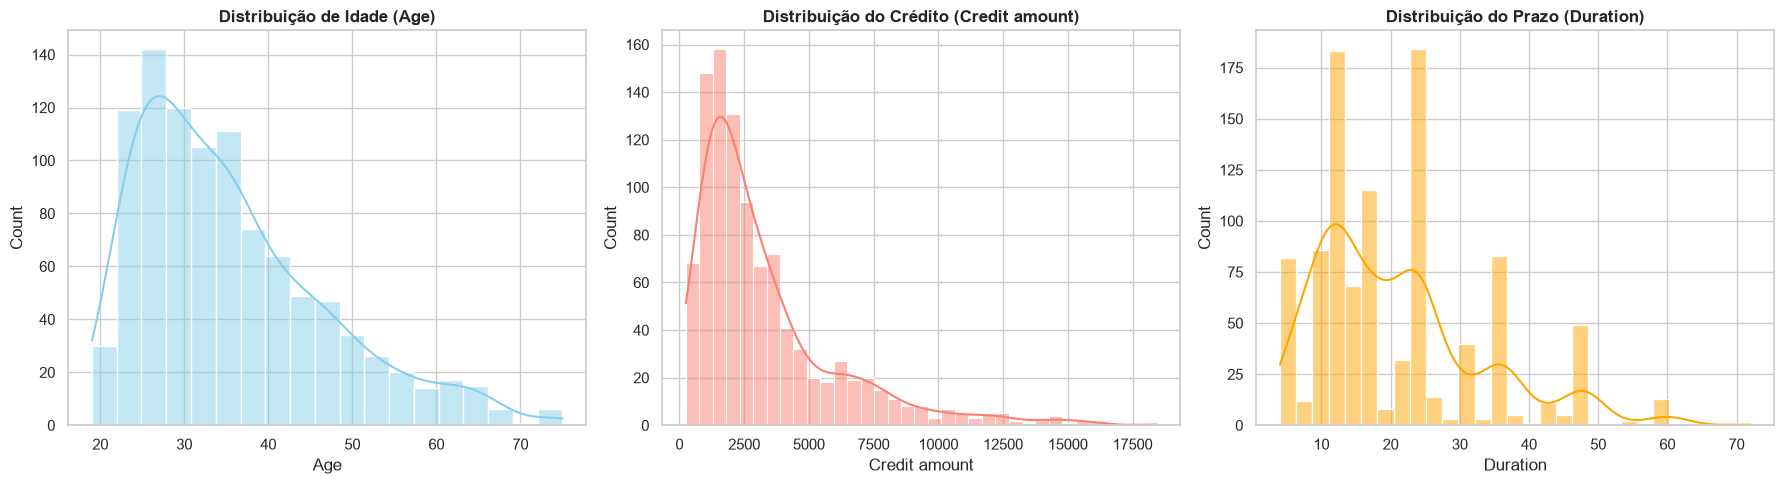

In [3]:
# Estatísticas descritivas das variáveis numéricas
print("--- Sumário Estatístico ---")
display(df[["Age", "Credit amount", "Duration"]].describe())

# Plotagem univariada de alta qualidade visual
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["Age"], kde=True, color="skyblue", ax=axes[0])
axes[0].set_title("Distribuição de Idade (Age)", fontsize=12, fontweight="bold")

sns.histplot(df["Credit amount"], kde=True, color="salmon", ax=axes[1])
axes[1].set_title("Distribuição do Crédito (Credit amount)", fontsize=12, fontweight="bold")

sns.histplot(df["Duration"], kde=True, color="orange", ax=axes[2])
axes[2].set_title("Distribuição do Prazo (Duration)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Análise de Correlação e Multicolinearidade
A matriz de correlação linear valida o alinhamento estrutural entre o prazo do empréstimo (`Duration`) e o montante solicitado (`Credit amount`), servindo como premissa analítica para o particionamento estratificado e simulação de cenários de desvio nas próximas etapas.

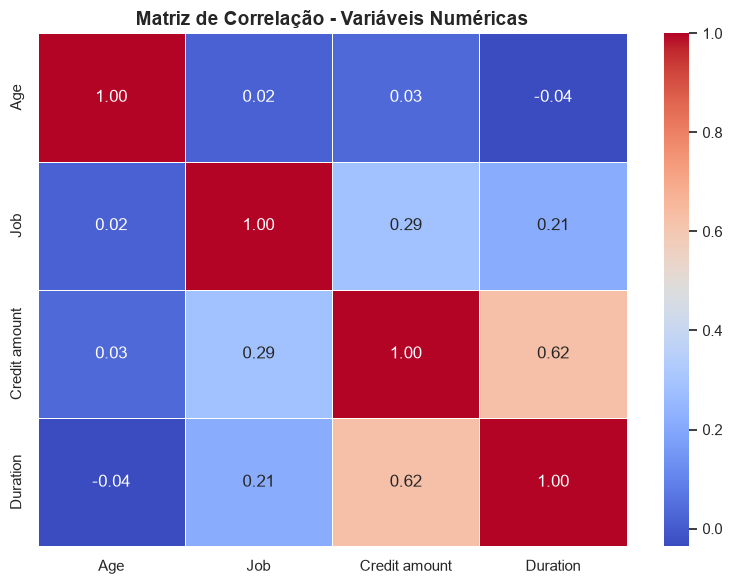

In [4]:
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=["int64", "float64"])
corr_matrix = numeric_cols.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Matriz de Correlação - Variáveis Numéricas", fontsize=14, fontweight="bold")
plt.show()